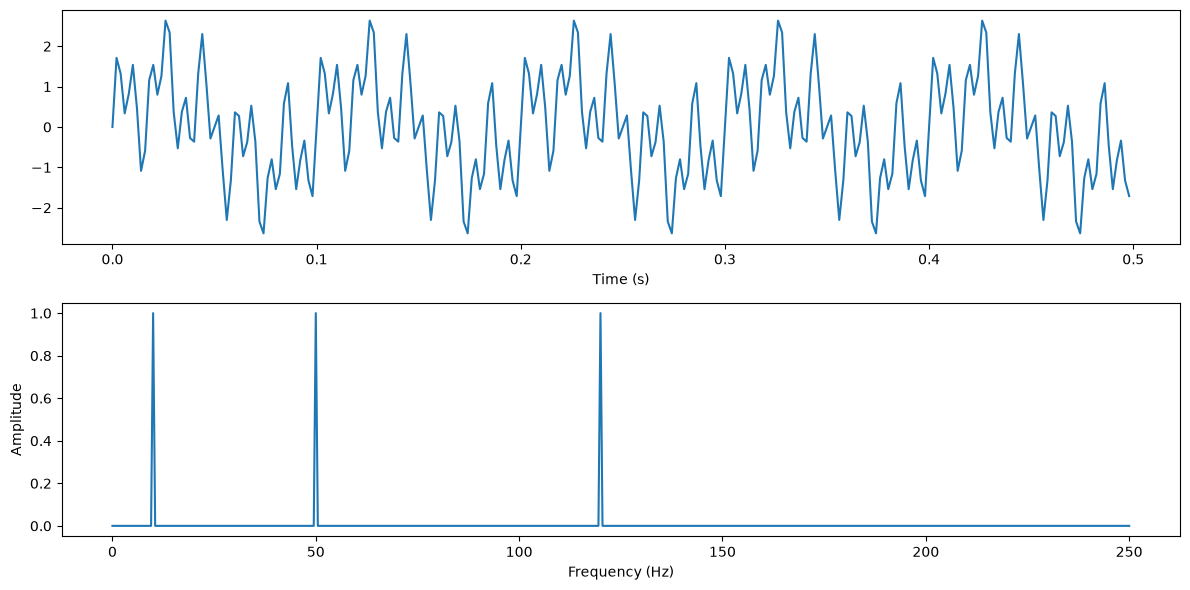

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fs = 500                      # sampling rate in Hz
t = np.arange(0, 2, 1/fs)     # 2 seconds of time points
x = np.sin(2*np.pi*10*t) + np.sin(2*np.pi*50*t) + np.sin(2*np.pi*120*t)    # 10 Hz + 50 Hz

spectrum = np.abs(np.fft.rfft(x)) / len(x) * 2
freqs = np.fft.rfftfreq(len(x), d=1/fs)

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ax[0].plot(t[:250], x[:250])
ax[0].set_xlabel('Time (s)')
ax[1].plot(freqs, spectrum)
ax[1].set_xlabel('Frequency (Hz)')
ax[1].set_ylabel('Amplitude')
plt.tight_layout()
plt.show()

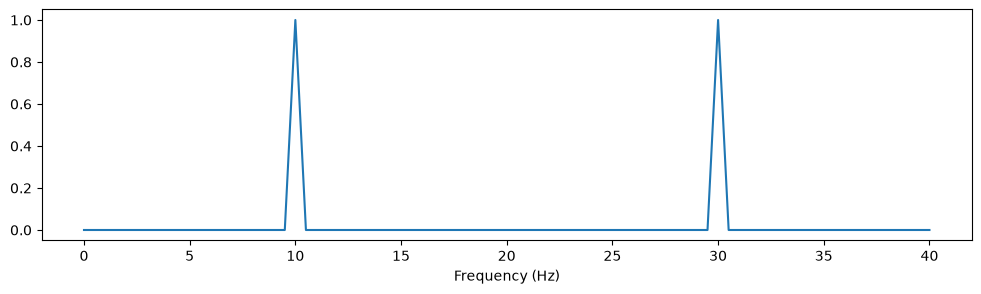

In [21]:
fs = 80
t = np.arange(0, 2, 1/fs)
x = np.sin(2*np.pi*10*t) + np.sin(2*np.pi*50*t)

spectrum = np.abs(np.fft.rfft(x)) / len(x) * 2
freqs = np.fft.rfftfreq(len(x), d=1/fs)

plt.figure(figsize=(12, 3))
plt.plot(freqs, spectrum)
plt.xlabel('Frequency (Hz)')
plt.show()

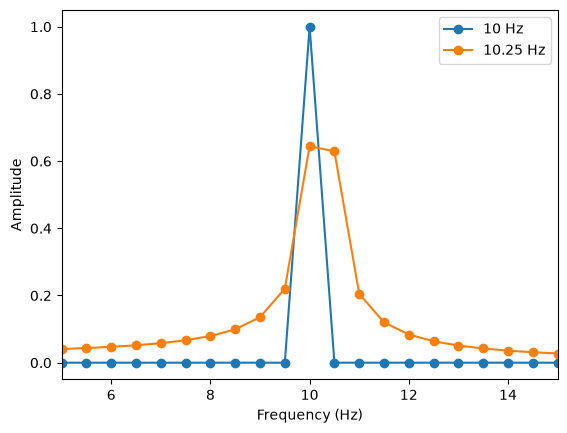

In [3]:
import numpy as np
import matplotlib.pyplot as plt

fs = 500
t = np.arange(0, 2, 1/fs)       # 2 seconds, so spacing = 1/2 = 0.5 Hz

for f in [10, 10.25]:
    x = np.sin(2*np.pi*f*t)
    spec = np.abs(np.fft.rfft(x)) / len(x) * 2
    freqs = np.fft.rfftfreq(len(x), d=1/fs)
    plt.plot(freqs, spec, 'o-', label=f'{f} Hz')

plt.xlim(5, 15)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

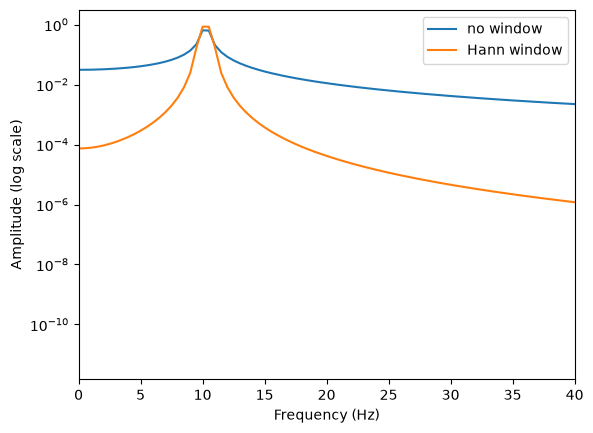

In [4]:
f = 10.25
x = np.sin(2*np.pi*f*t)

w = np.hanning(len(x))
spec_rect = np.abs(np.fft.rfft(x)) / len(x) * 2
spec_hann = np.abs(np.fft.rfft(x * w)) / (np.sum(w) / 2)
freqs = np.fft.rfftfreq(len(x), d=1/fs)

plt.semilogy(freqs, spec_rect, label='no window')
plt.semilogy(freqs, spec_hann, label='Hann window')
plt.xlim(0, 40)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude (log scale)')
plt.legend()
plt.show()

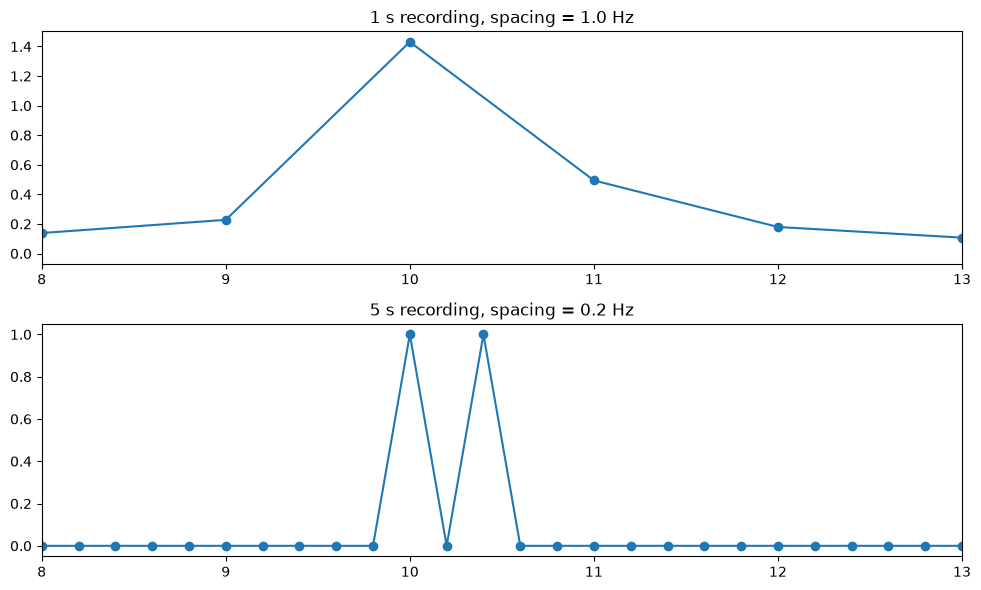

In [8]:
fs = 500
fig, ax = plt.subplots(2, 1, figsize=(10, 6))

for a, dur in zip(ax, [1, 5]):
    t = np.arange(0, dur, 1/fs)
    x = np.sin(2*np.pi*10*t) + np.sin(2*np.pi*10.4*t)
    spec = np.abs(np.fft.rfft(x)) / len(x) * 2
    freqs = np.fft.rfftfreq(len(x), d=1/fs)
    a.plot(freqs, spec, 'o-')
    a.set_xlim(8, 13)
    a.set_title(f'{dur} s recording, spacing = {1/dur} Hz')

plt.tight_layout()
plt.show()